# Findings: when does data cleaning actually help?

This notebook backs up every number in the [README](../README.md). It reads the saved experiment results (`results/experiments.parquet`: 11,520 trained models, 20 seeds) and recomputes each finding from them. Nothing is hard-coded.

**Running it** takes a few seconds and doesn't rerun the 5.5-hour experiment. Use `python -m src.run_experiment` to regenerate the results from scratch.

**Reading the evidence.** Each comparison is *paired*: both strategies are scored on the same seed, which means the same train/holdout split and the same corrupted cells. For each comparison the notebook reports:
- the mean difference,
- its standard deviation across seeds,
- how many of the 20 seeds went the same way ("wins").

Wins of 20/20 mean the effect isn't seed noise.

**Contents**
0. Setup
1. The dataset
2. Integrity of the results
3. Finding 1: why data is missing matters more than how much
4. Finding 2: a missing-value flag helps or hurts depending on the deployment data
5. Finding 3: tree models build that flag on their own; linear models can't
6. Finding 4: dropping rows is the most damaging strategy
7. Finding 5: recovering true values ≠ a better model
8. Finding 6: fuzzy matching has a built-in limit on word length
9. All the evidence in one table

## 0. Setup

In [2]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from rapidfuzz import fuzz

# find the project root, so the notebook works from any working directory
project_dir = Path.cwd()
while not (project_dir / "config.yaml").exists():
    project_dir = project_dir.parent

import sys

sys.path.insert(0, str(project_dir))
from src import plots  # noqa: E402

config = yaml.safe_load((project_dir / "config.yaml").open())
results = pd.read_parquet(project_dir / "results/experiments.parquet")

# figures are drawn inline; the plot functions also save files, so send those to a temp folder
plots.project_dir = Path(tempfile.mkdtemp())
(plots.project_dir / "figures").mkdir()
plt.rcParams["figure.dpi"] = 80

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

In [2]:
def mean_table(df, index, columns, metric, **filters):
    """Mean of `metric` over seeds, after filtering on column == value."""
    for column, value in filters.items():
        df = df[df[column] == value]
    return df.pivot_table(index=index, columns=columns, values=metric, aggfunc="mean")


def paired(claim, model, corruption_type, condition, rate, a, b, metric="roc_auc"):
    """Paired comparison of strategy b against strategy a over the 20 seeds."""
    d = results[
        (results["model"] == model)
        & (results["corruption_type"] == corruption_type)
        & (results["holdout_condition"] == condition)
        & (results["corruption_rate"] == rate)
    ]
    x = d[d["strategy"] == a].set_index("seed")[metric]
    y = d[d["strategy"] == b].set_index("seed")[metric]
    diff = (y - x).dropna()
    wins = int((diff > 0).sum()) if diff.mean() > 0 else int((diff < 0).sum())
    return {
        "claim": claim,
        "model": model,
        "mechanism": corruption_type,
        "deployed on": condition,
        "rate": rate,
        "metric": metric,
        "A": a,
        "A mean": x.mean(),
        "B": b,
        "B mean": y.mean(),
        "B - A": diff.mean(),
        "sd of diff": diff.std(),
        "consistent seeds": f"{wins}/{len(diff)}",
    }


evidence = []  # every paired comparison in the notebook is collected here for section 9

## 1. The dataset

[Hotel Booking Demand](https://doi.org/10.1016/j.dib.2018.11.126) (Antonio, Almeida & Nunes, 2019). The task is to predict `is_canceled`. The full processed file is git-ignored; if it isn't present, the notebook falls back to the 2,000-row sample committed for the tests.

In [3]:
full_path = project_dir / f"data/processed/csv_{config['target_column']}.csv"
sample_path = project_dir / "tests/data/hotel_bookings_sample.csv"
data_path = full_path if full_path.exists() else sample_path
data = pd.read_csv(data_path)

continuous = config["columns"]["continuous"]
categorical = config["columns"]["categorical"]

print(f"source: {data_path.relative_to(project_dir)}")
print(f"rows: {len(data):,}   features: {len(continuous)} numeric + {len(categorical)} categorical")
print(f"cancellation rate: {data[config['target_column']].mean():.1%}")

source: data/processed/csv_is_canceled.csv
rows: 86,426   features: 9 numeric + 11 categorical
cancellation rate: 27.4%


In [4]:
# the 9 numeric columns that the missing-value mechanisms corrupt
# note the scales: lead_time and adr are in the hundreds, adults in single digits
data[continuous].describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
lead_time,80.059,85.945,0.0,49.0,737.0
adr,106.747,51.855,0.0,99.0,510.0
stays_in_weekend_nights,1.008,1.028,0.0,1.0,19.0
stays_in_week_nights,2.631,2.040,0.0,2.0,50.0
adults,1.882,0.622,0.0,2.0,55.0
children,0.140,0.458,0.0,0.0,10.0
total_of_special_requests,0.702,0.833,0.0,1.0,5.0
booking_changes,0.270,0.713,0.0,0.0,18.0
arrival_date_week_number,26.849,13.649,1.0,27.0,53.0


In [5]:
# the categorical columns; typo_corruption only touches the four in typo_columns
pd.DataFrame({
    "distinct values": data[categorical].nunique(),
    "most common": data[categorical].agg(lambda s: s.value_counts().index[0]),
    "gets typos": [c in config["columns"]["typo_columns"] for c in categorical],
})

,distinct values,most common,gets typos
hotel,2,City Hotel,False
arrival_date_month,12,August,True
meal,5,BB,False
country,178,PRT,False
market_segment,7,Online TA,True
distribution_channel,5,TA/TO,False
reserved_room_type,9,A,False
assigned_room_type,11,A,False
deposit_type,3,No Deposit,True
customer_type,4,Transient,True


## 2. Integrity of the results

Every combination should have 20 seeds × 6 rates = 120 rows. Some model fits fail by design:
- **Logistic regression can't handle missing values,** so "do nothing" fails under every missing-value mechanism. Fuzzy matching only fixes typos and leaves missing values alone, so it fails too.
- **Drop-rows can leave only one class.** Under label-correlated missingness from 40% onward, it removes every cancelled booking.

These failures are recorded as `model_failed` rather than silently dropped.

In [6]:
group_sizes = results.groupby(["model", "corruption_type", "strategy", "holdout_condition"]).size()
print(f"{len(results):,} rows; every combination has {group_sizes.min()}-{group_sizes.max()} rows")

failed = results[results["model_failed"]]
failed.groupby(["corruption_type", "strategy", "model", "holdout_condition"]).size().unstack(fill_value=0)

11,520 rows; every combination has 120-120 rows


holdout_condition                            clean  corrupted
corruption_type          strategy    model                   
label_correlated_missing do_nothing  logreg    100        100
                         drop_rows   hgb        44         44
                                     logreg     44        100
                         fuzzy_match logreg    100        100
random_missing_values    do_nothing  logreg    100        100
                         drop_rows   logreg      0        100
                         fuzzy_match logreg    100        100
self_masking_missing     do_nothing  logreg    100        100
                         drop_rows   logreg      0        100
                         fuzzy_match logreg    100        100

## 3. Finding 1: why data is missing matters more than how much

All three missing-value mechanisms remove **the same number of cells from the same 9 numeric columns**. Only *which* cells go missing differs. Here: gradient boosting, no cleaning, deployed on clean data.

In [7]:
missing_mechanisms = ["random_missing_values", "self_masking_missing", "label_correlated_missing"]
d = results[
    (results["model"] == "hgb")
    & (results["strategy"] == "do_nothing")
    & (results["holdout_condition"] == "clean")
    & (results["corruption_type"].isin(missing_mechanisms))
]
d.pivot_table(index="corruption_type", columns="corruption_rate", values=["roc_auc", "f1"], aggfunc="mean").loc[
    missing_mechanisms
]

f1                                    roc_auc                                   
corruption_rate             0.0    0.1    0.2    0.3    0.4    0.5     0.0    0.1    0.2    0.3    0.4    0.5
corruption_type                                                                                              
random_missing_values     0.643  0.639  0.633  0.627  0.625  0.619   0.878  0.877  0.875  0.872  0.871  0.868
self_masking_missing      0.643  0.638  0.637  0.635  0.627  0.615   0.878  0.876  0.874  0.873  0.868  0.862
label_correlated_missing  0.643  0.270  0.085  0.046  0.000  0.000   0.878  0.873  0.862  0.836  0.738  0.527

Under label-correlated missingness, the model learns that a missing value means "cancelled". Clean production data never has missing values, so the model predicts "not cancelled" for everyone. AUC (ranking) barely moves at 10% while F1 collapses:

AUC at 10% vs uncorrupted: -0.6%
F1  at 10% vs uncorrupted: -58.0%


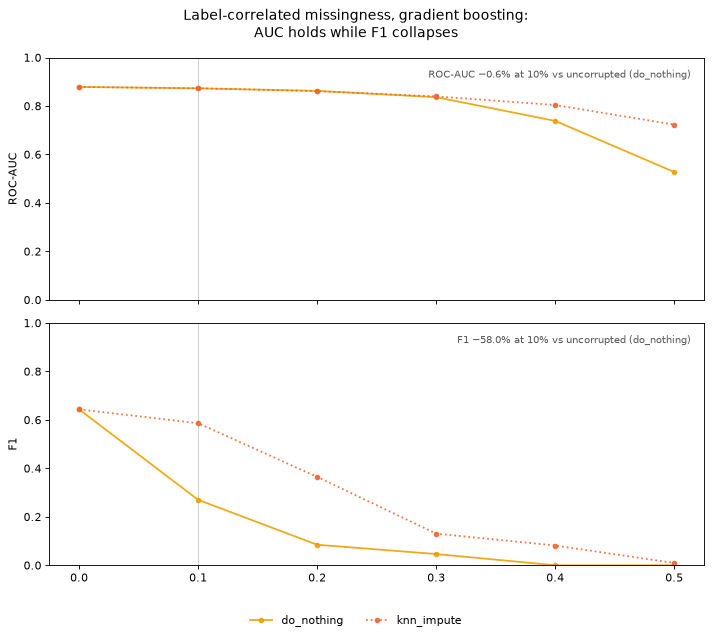

In [8]:
base = mean_table(results, "corruption_rate", None, "roc_auc", model="hgb", strategy="do_nothing",
                  holdout_condition="clean", corruption_type="label_correlated_missing")
f1 = mean_table(results, "corruption_rate", None, "f1", model="hgb", strategy="do_nothing",
                holdout_condition="clean", corruption_type="label_correlated_missing")
print(f"AUC at 10% vs uncorrupted: {base.loc[0.1].item() / base.loc[0.0].item() - 1:+.1%}")
print(f"F1  at 10% vs uncorrupted: {f1.loc[0.1].item() / f1.loc[0.0].item() - 1:+.1%}")

plots.divergence(plots.holdout(results, "clean"))
plt.show()

## 4. Finding 2: a missing-value flag helps or hurts depending on the deployment data

`mean_fill_indicator` is mean fill plus one 0/1 "was missing" column per numeric feature. Its effect reverses depending on whether the data the model is deployed on has the same missingness as the training data.

In [9]:
rows = [
    paired("flag hurts when deployment data is clean", "logreg", "label_correlated_missing", "clean", 0.1,
           "mean_fill", "mean_fill_indicator", "f1"),
    paired("flag helps when deployment data is equally corrupted", "logreg", "label_correlated_missing", "corrupted",
           0.1, "mean_fill", "mean_fill_indicator", "f1"),
    paired("under true MNAR, flag helps on corrupted deployment", "logreg", "self_masking_missing", "corrupted", 0.5,
           "mean_fill", "mean_fill_indicator"),
    paired("...and doesn't hurt on clean deployment", "logreg", "self_masking_missing", "clean", 0.5,
           "mean_fill", "mean_fill_indicator"),
]
evidence += rows
pd.DataFrame(rows).drop(columns=["model"]).set_index("claim")

,mechanism,deployed on,rate,metric,A,A mean,B,B mean,B - A,sd of diff,consistent seeds
claim,,,,,,,,,,,
flag hurts when deployment data is clean,label_correlated_missing,clean,0.1,f1,mean_fill,0.528,mean_fill_indicator,0.190,-0.338,0.014,20/20
flag helps when deployment data is equally corrupted,label_correlated_missing,corrupted,0.1,f1,mean_fill,0.496,mean_fill_indicator,0.679,0.183,0.010,20/20
"under true MNAR, flag helps on corrupted deployment",self_masking_missing,corrupted,0.5,roc_auc,mean_fill,0.780,mean_fill_indicator,0.813,0.034,0.004,20/20
...and doesn't hurt on clean deployment,self_masking_missing,clean,0.5,roc_auc,mean_fill,0.776,mean_fill_indicator,0.780,0.004,0.005,14/20


The last row isn't consistent across seeds (an effect of +0.004 in only some seeds), so the safe reading is "**no harm**", not "helps".

In the figure, the top row is deployment on clean data and the bottom row is deployment on equally corrupted data. The label-correlated, corrupted panel reaches AUC ≈ 1.0 because missingness there is *generated from the label*. That's leakage by construction: treat it as an upper bound, not a realistic score.

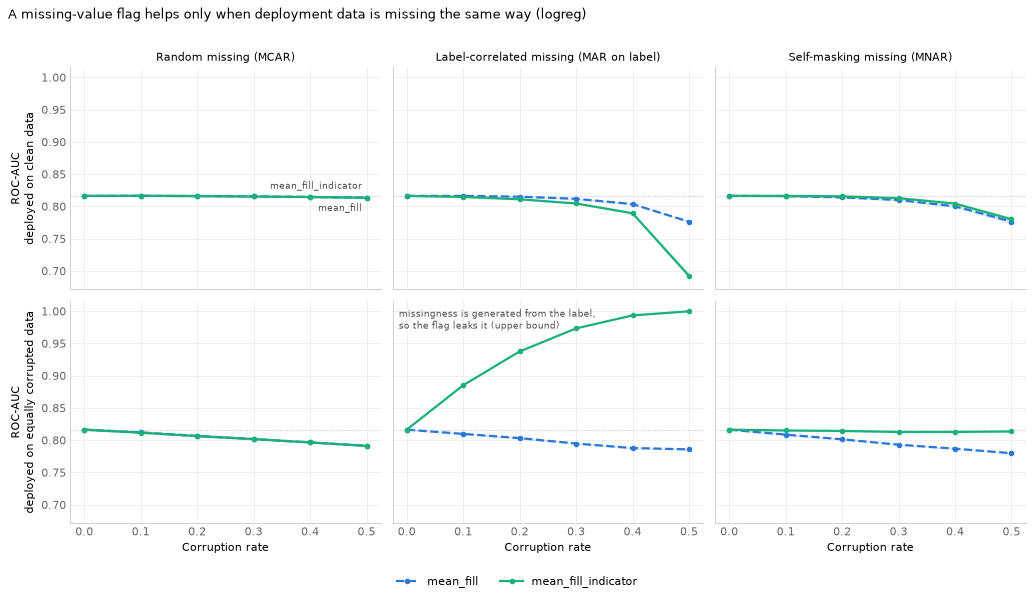

In [10]:
plots.indicator_vs_deployment(results, "logreg")
plt.show()

## 5. Finding 3: tree models build that flag on their own; linear models can't

Mean fill writes **the same number** into every gap. A gradient-boosted tree can split on "value == column mean", which works like a flag. A linear model can't, because the mean sits in the middle of the range. So on corrupted deployment data, gradient boosting gains nothing from an explicit flag, while logistic regression gains a lot:

In [11]:
mean_table(results, "model", "strategy", "roc_auc", corruption_type="label_correlated_missing",
           holdout_condition="corrupted", corruption_rate=0.5)[["mean_fill", "mean_fill_indicator"]]

strategy,mean_fill,mean_fill_indicator
model,,
hgb,1.000,1.0
logreg,0.786,1.0


The same reasoning explains which imputer works best for trees when deployment data is clean. KNN fills each gap with a *different* value, so there's no single number for the tree to latch onto:

In [12]:
rows = [
    paired("KNN is the most robust imputer for trees on clean deployment", "hgb", "label_correlated_missing", "clean",
           0.5, "do_nothing", "knn_impute"),
]
evidence += rows
pd.DataFrame(rows).set_index("claim")

,model,mechanism,deployed on,rate,metric,A,A mean,B,B mean,B - A,sd of diff,consistent seeds
claim,,,,,,,,,,,,
KNN is the most robust imputer for trees on clean deployment,hgb,label_correlated_missing,clean,0.5,roc_auc,do_nothing,0.527,knn_impute,0.723,0.196,0.038,20/20


## 6. Finding 4: dropping rows is the most damaging strategy

A row survives only if **all 9** numeric values are present, so at rate *p* about (1 − p)⁹ of rows remain under random missingness. Under label-correlated missingness, cancelled bookings are removed first.

In [13]:
rows_kept = mean_table(results, "corruption_rate", "corruption_type", "n_rows_trained", model="hgb",
                       strategy="drop_rows", holdout_condition="clean")
rows_kept = rows_kept[missing_mechanisms].round(0)
rows_kept["theory: 16,000 × (1 - p)^9"] = (16000 * (1 - rows_kept.index.to_series()) ** 9).round(0)
rows_kept

corruption_type,random_missing_values,self_masking_missing,label_correlated_missing,"theory: 16,000 × (1 - p)^9"
corruption_rate,,,,
0.0,16000.0,16000.0,16000.0,16000.0
0.1,6204.0,6466.0,6993.0,6199.0
0.2,2155.0,2553.0,3387.0,2147.0
0.3,652.0,980.0,1668.0,646.0
0.4,163.0,351.0,776.0,161.0
0.5,30.0,123.0,342.0,31.0


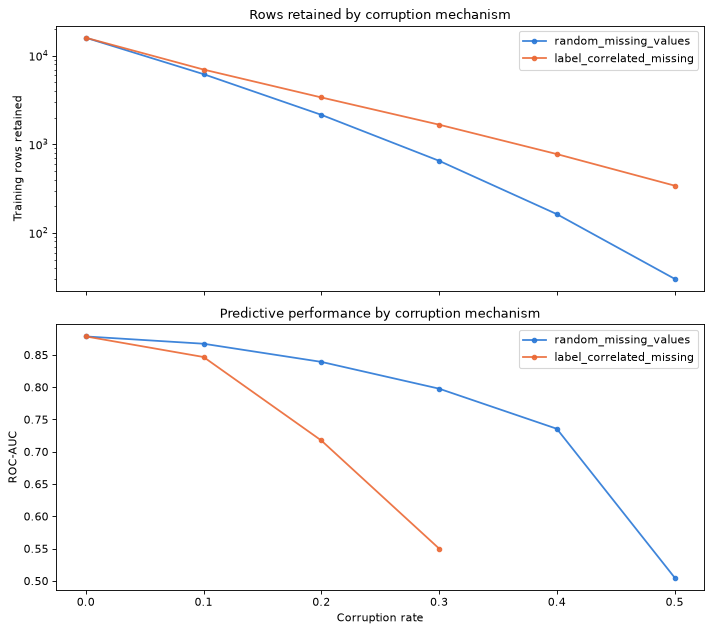

In [14]:
plots.section_bias(plots.holdout(results, "clean"))
plt.show()

## 7. Finding 5: recovering the true values ≠ a better model

These are recovery metrics on the corrupted cells only, pooled over the 9 numeric columns in raw units (so `lead_time` and `adr` dominate). Bias is *true − imputed*, so a positive bias means the imputer underestimates.

In [15]:
recovery = results[
    results["recovery_applicable"].eq(True)
    & (results["model"] == "hgb")
    & (results["holdout_condition"] == "clean")  # recovery only depends on train, avoid double counting
    & (results["strategy"].isin(["mean_fill", "knn_impute"]))
]
recovery.groupby(["corruption_type", "strategy"])[["rmse", "wasserstein", "bias"]].mean().loc[missing_mechanisms]

rmse  wasserstein    bias
corruption_type          strategy                               
random_missing_values    knn_impute  36.695        5.215   0.347
                         mean_fill   33.288        9.982  -0.005
self_masking_missing     knn_impute  52.455       19.721  19.720
                         mean_fill   53.670       21.948  21.795
label_correlated_missing knn_impute  38.253        5.941   0.203
                         mean_fill   34.520        9.868   2.035

- **Random missingness:** mean fill has the lowest RMSE but about twice KNN's Wasserstein distance, because it stacks every gap on one value and distorts the distribution.
- **Self-masking:** both imputers underestimate by about 20 units, because the values that went missing are exactly the high ones that the observed data under-represents. No imputation method that only looks at the observed values can fix that.

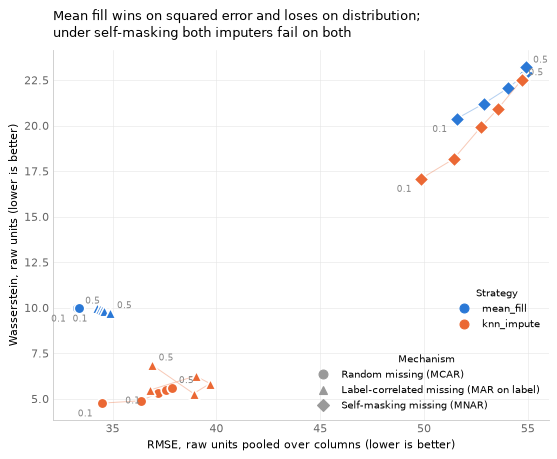

In [16]:
plots.recovery_disconnect(plots.holdout(results, "clean"))
plt.show()

## 8. Finding 6: fuzzy matching has a built-in limit on word length

Each typo replaces one character. RapidFuzz's `ratio` counts that as 2 edits out of 2n characters, so a one-character typo in an *n*-character word scores **(n − 1)/n**. With a threshold of 85, only words of **7 or more** characters can ever be fixed. Checking this against the real categories:

In [17]:
threshold = config["strategy_params"]["fuzzy_match"].get("threshold", 85)

rows = []
for column in config["columns"]["typo_columns"]:
    for value in sorted(data[column].dropna().unique()):
        word = value.lower()
        typo = "#" + word[1:]  # one substituted character
        score = fuzz.ratio(word, typo)
        rows.append({"column": column, "category": value, "length": len(word),
                     "score after one typo": round(score, 1), "fixable": score >= threshold})

word_check = pd.DataFrame(rows)
print(f"fixable categories: {word_check['fixable'].sum()} of {len(word_check)}")
word_check.sort_values(["fixable", "length"]).head(12)

fixable categories: 17 of 26


,column,category,length,score after one typo,fixable
19,arrival_date_month,May,3,66.7,False
16,arrival_date_month,July,4,75.0,False
17,arrival_date_month,June,4,75.0,False
8,customer_type,Group,5,80.0,False
11,arrival_date_month,April,5,80.0,False
18,arrival_date_month,March,5,80.0,False
3,market_segment,Direct,6,83.3,False
4,market_segment,Groups,6,83.3,False
12,arrival_date_month,August,6,83.3,False
15,arrival_date_month,January,7,85.7,True


In [18]:
buckets = results[
    (results["corruption_type"] == "typo_corruption")
    & (results["strategy"] == "fuzzy_match")
    & (results["model"] == "hgb")
    & (results["holdout_condition"] == "clean")
    & (results["corruption_rate"] > 0)
]
buckets.groupby("corruption_rate")[["cat_match_rate", "cat_untouched_rate", "cat_wrong_label_rate"]].mean()

,cat_match_rate,cat_untouched_rate,cat_wrong_label_rate
corruption_rate,,,
0.1,0.801,0.159,0.040
0.2,0.802,0.144,0.054
0.3,0.802,0.137,0.061
0.4,0.802,0.132,0.066
0.5,0.801,0.129,0.069


Fuzzy matching matters most when production data also has typos **and** the model is linear. One-hot encoding turns every unseen misspelling into an all-zero row, so the linear model loses that feature completely.

In [19]:
rows = [
    paired("fuzzy matching rescues a linear model on dirty deployment", "logreg", "typo_corruption", "corrupted", 0.5,
           "do_nothing", "fuzzy_match"),
    paired("gradient boosting barely needs it", "hgb", "typo_corruption", "corrupted", 0.5,
           "do_nothing", "fuzzy_match"),
]
evidence += rows
pd.DataFrame(rows).set_index("claim")

,model,mechanism,deployed on,rate,metric,A,A mean,B,B mean,B - A,sd of diff,consistent seeds
claim,,,,,,,,,,,,
fuzzy matching rescues a linear model on dirty deployment,logreg,typo_corruption,corrupted,0.5,roc_auc,do_nothing,0.662,fuzzy_match,0.772,0.110,0.010,20/20
gradient boosting barely needs it,hgb,typo_corruption,corrupted,0.5,roc_auc,do_nothing,0.873,fuzzy_match,0.878,0.005,0.002,20/20


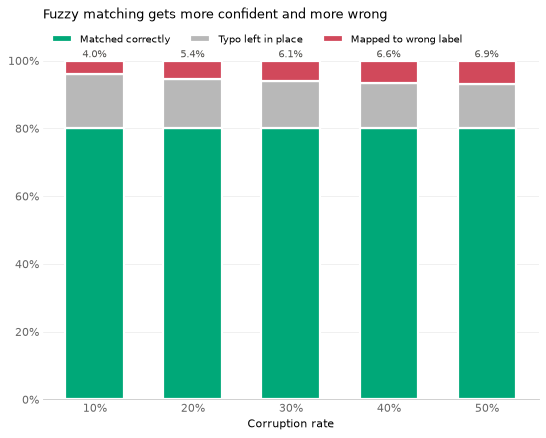

In [20]:
plots.fuzzy_bucket_composition(plots.holdout(results, "clean"))
plt.show()

## 9. All the evidence in one table

Every paired comparison from this notebook. **B − A** is the mean paired difference over seeds. **Consistent seeds** counts how many of the 20 seeds went the same direction as the mean.

In [21]:
summary = pd.DataFrame(evidence).set_index("claim")
summary[["model", "mechanism", "deployed on", "rate", "metric", "A", "B", "A mean", "B mean", "B - A",
         "sd of diff", "consistent seeds"]]

,model,mechanism,deployed on,rate,metric,A,B,A mean,B mean,B - A,sd of diff,consistent seeds
claim,,,,,,,,,,,,
flag hurts when deployment data is clean,logreg,label_correlated_missing,clean,0.1,f1,mean_fill,mean_fill_indicator,0.528,0.190,-0.338,0.014,20/20
flag helps when deployment data is equally corrupted,logreg,label_correlated_missing,corrupted,0.1,f1,mean_fill,mean_fill_indicator,0.496,0.679,0.183,0.010,20/20
"under true MNAR, flag helps on corrupted deployment",logreg,self_masking_missing,corrupted,0.5,roc_auc,mean_fill,mean_fill_indicator,0.780,0.813,0.034,0.004,20/20
...and doesn't hurt on clean deployment,logreg,self_masking_missing,clean,0.5,roc_auc,mean_fill,mean_fill_indicator,0.776,0.780,0.004,0.005,14/20
KNN is the most robust imputer for trees on clean deployment,hgb,label_correlated_missing,clean,0.5,roc_auc,do_nothing,knn_impute,0.527,0.723,0.196,0.038,20/20
fuzzy matching rescues a linear model on dirty deployment,logreg,typo_corruption,corrupted,0.5,roc_auc,do_nothing,fuzzy_match,0.662,0.772,0.110,0.010,20/20
gradient boosting barely needs it,hgb,typo_corruption,corrupted,0.5,roc_auc,do_nothing,fuzzy_match,0.873,0.878,0.005,0.002,20/20


### Limitations

- **One dataset.** The direction of each effect follows from how the mechanism works, but the sizes are specific to this data.
- **Label-correlated + corrupted deployment is label leakage by construction** (the AUC ≈ 1.0 cases), so treat it as an upper bound.
- **F1 uses a fixed 0.5 threshold,** so it also reflects calibration shifts. ROC-AUC is the primary metric.
- **Recovery metrics are pooled across columns in raw units.**
- **Corruption is synthetic,** and cleaner settings (k = 3, threshold 85) were not tuned.